# Cleaning Gemini GMOS images with easyspec

In this tutorial we reduce a set of GMOS-N images, from the raw files of the Gemini archive to a single clean, combined image, ready for photometry. The data are the "starfield" tutorial package of the Gemini DRAGONS pipeline:

- 5 exposures of 10 s of a star field in the **i** filter, with small telescope offsets between them (*dithers*);
- 10 bias frames;
- 5 twilight flats in the i filter;
- the static bad pixel mask (BPM) of the detector.

All frames were taken with 2x2 binning. GMOS has a mosaic of three CCDs separated by gaps of ~3 arcsec, and each CCD is read through four amplifiers. The dithers move the stars on the detector, so the regions lost in the gaps of one exposure are covered by the other exposures.

The steps:

1. convert the raw GMOS files into single images that easyspec can read (`gmos.convert()`);
2. bias, flat field, cosmic rays and variance with `cleaning()`;
3. align the 5 exposures and combine them into one image.


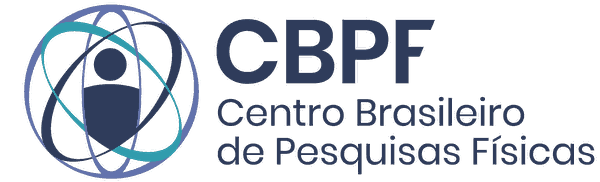

In [1]:
from pathlib import Path
import numpy as np
from easyspec.gemini import gmos
from easyspec.cleaning import cleaning

cleaning = cleaning()

## Step 1. Converting the raw GMOS data

A raw GMOS frame has one fits extension per amplifier (12 for the Hamamatsu CCDs), each with its own overscan region, gain and read noise. First, let's see what we have in the raw data directory:

In [2]:
raw_data = Path("./Gemini_GMOS_starfield")   # Raw GMOS files
table = gmos.inventory(raw_data)

                     file                         category      mode     object  filter grating central_wavelength    mask   binning  rows  exposure q_offset
---------------------------------------------- -------------- -------- --------- ------ ------- ------------------ --------- ------- ------ -------- --------
                       N20170613S0180.fits.bz2           bias longslit      Bias   open   B1200              480.0 1.0arcsec     2x2 1-4224      0.0      0.0
                       N20170613S0181.fits.bz2           bias longslit      Bias   open   B1200              480.0 1.0arcsec     2x2 1-4224      0.0      0.0
                       N20170613S0182.fits.bz2           bias longslit      Bias   open   B1200              480.0 1.0arcsec     2x2 1-4224      0.0      0.0
                       N20170613S0183.fits.bz2           bias longslit      Bias   open   B1200              480.0 1.0arcsec     2x2 1-4224      0.0      0.0
                       N20170613S0184.fits.bz2      

`gmos.convert()` subtracts the overscan of each amplifier, converts it to electrons with its own gain, assembles the three CCDs into a single image (the gaps between the CCDs and the bad pixels of the BPM are set to NaN), and sorts the frames into the directories that `cleaning()` expects. The converted images are in electrons, so their header has `GAIN = 1`; the read noise (`RDNOISE`) and the saturation level (`SATURATE`) are also in electrons. For imaging, all the dithered exposures of a field go to the same directory: they are aligned later by `cleaning.align()`.

This step only needs to be run once.

In [3]:
setup_paths = gmos.convert(raw_data,                 # Directory with the raw files (.fits or .fits.bz2)
                                  "gmos_converted",         # Output directory
                                  bad_pixel_mask="auto",    # Use the BPM file found among the raw files
                                  overscan="row",           # Overscan level subtracted row by row
                                  units="electron",         # Each amplifier is multiplied by its own gain
                                  overwrite=True)

20 frames converted into 1 setup(s):

  imaging_i_2x2   (image shape 2112x3140, detector rows 1-4224)
      bias/                                  10 frame(s)
      flat/                                   5 frame(s)
      target_starfield/                       5 frame(s)   exposure 10 s, airmass 1.00

Use: raw = cleaning.data_paths(**setups["<setup name>"])


## Step 2. Image reduction

We give the directories of the converted frames to `data_paths()`:

In [4]:
converted_data = Path("./gmos_converted/imaging_i_2x2")

all_raw_data = cleaning.data_paths(bias=converted_data/"bias",
                                   flats=converted_data/"flat",
                                   targets=converted_data/"target_starfield",
                                   data_file_extension="fits")

Let's have a look at the 5 exposures of the field. The images are shown in a logarithmic scale (`vmin` and `vmax` are the limits of log10 of the counts). The two vertical white stripes are the gaps between the CCDs (NaN), and the dark corners are outside the field of view of GMOS. Notice how the stars move from one exposure to the other:

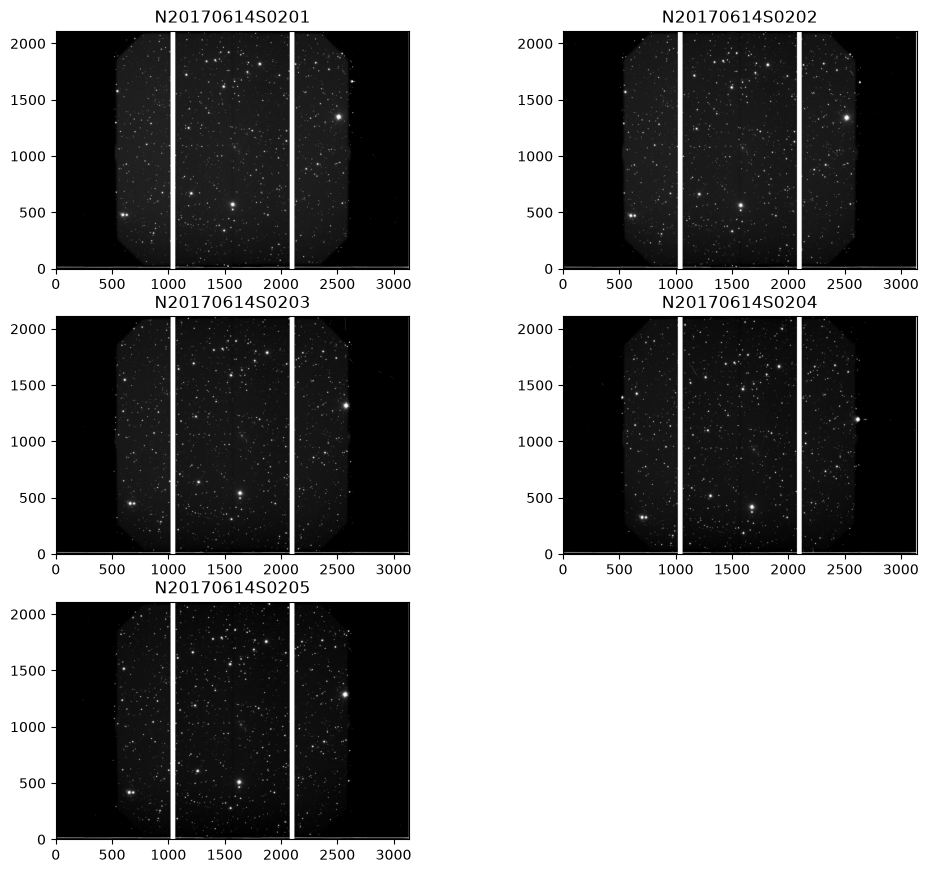

In [5]:
cleaning.plot_images(datacube=all_raw_data, image_type="target", Ncols=2, vmin=2.8, vmax=3.6, vertical_scale=3.5)

### Bias

The overscan level was already subtracted by `gmos.convert()`, so the master bias contains only the residual structure of the bias (a few electrons). The images are not trimmed: the overscan regions were removed during the conversion.

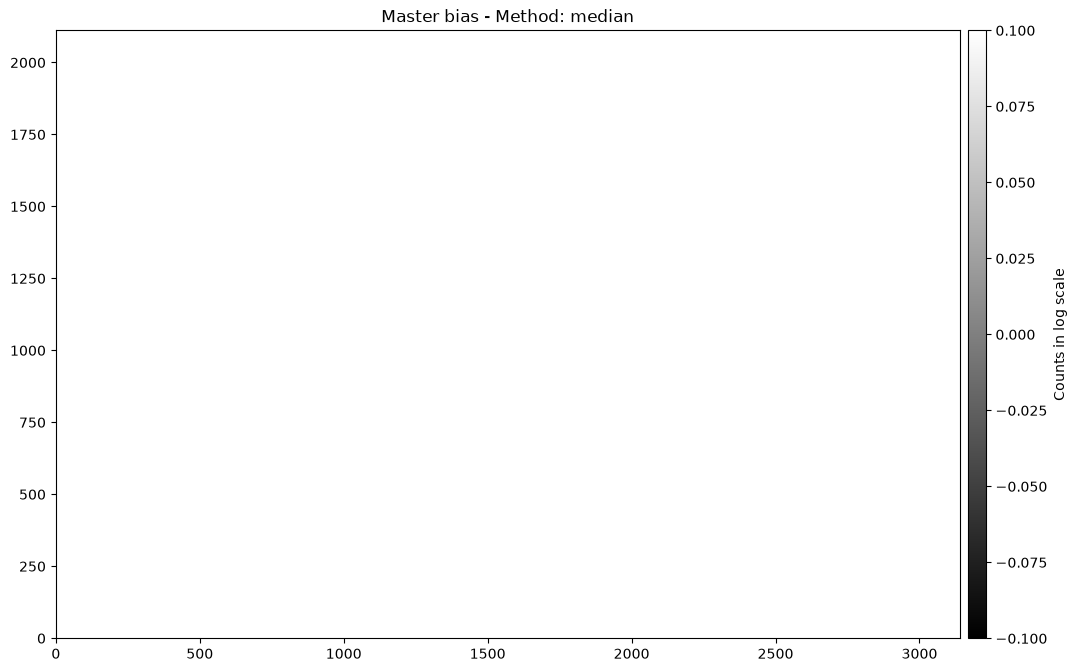

In [6]:
master_bias = cleaning.master("bias", all_raw_data, method="median", header_hdu_entry=0, plot=True)

In [7]:
debiased_data = cleaning.debias(all_raw_data, masterbias=master_bias, Type="all", pad_with_zeros=False)

### Flat field

The twilight flats are combined with a median (each flat is first scaled to the median level of the group, since the sky gets darker from one twilight exposure to the next). With `method="imaging"`, the master flat is divided by a single number, its level: the normalized flat keeps the whole structure of the response of the instrument, i.e. the vignetting at the edges of the field, the dust donuts, and the different sensitivities of the three CCDs and of the amplifiers.

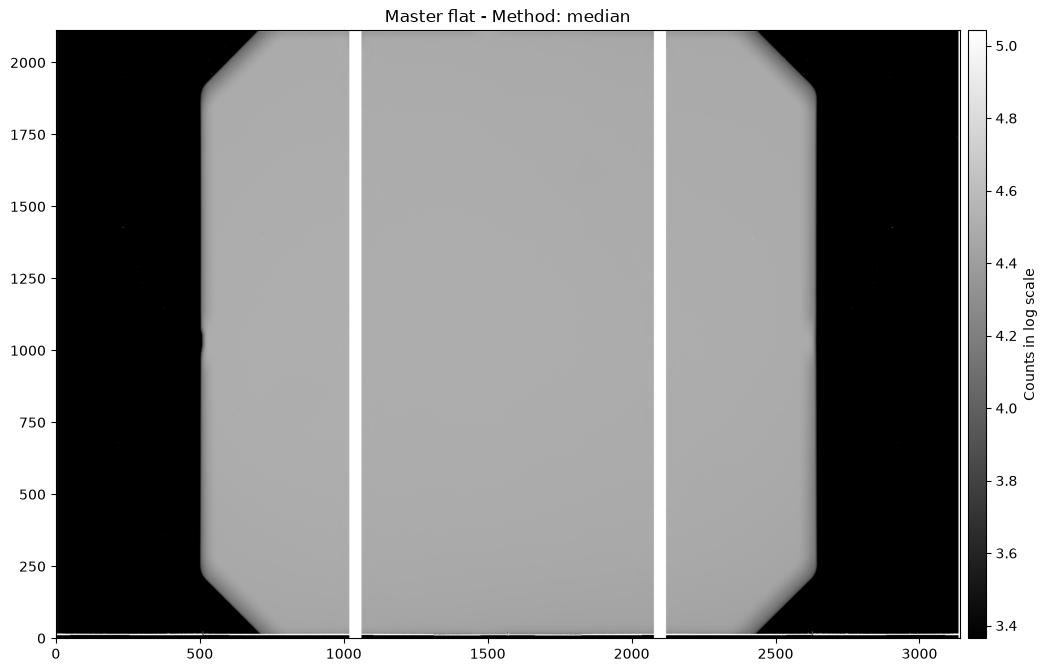

In [8]:
master_flat = cleaning.master("flat", debiased_data, method="median", header_hdu_entry=0, exposure_header_entry=None, plot=True)

/home/raniere/miniforge3/envs/easyspec/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


Normalized master flat: 2098/2112 illuminated rows; median = 0.9843; robust scatter = 0.0275; 2404423 pixels set to 1 (low signal).
163 bad columns identified (excluded from the model, corrected by the flat).
Relative noise per pixel of the master flat: median 0.29%, from 0.28% to 3.58% depending on the column.


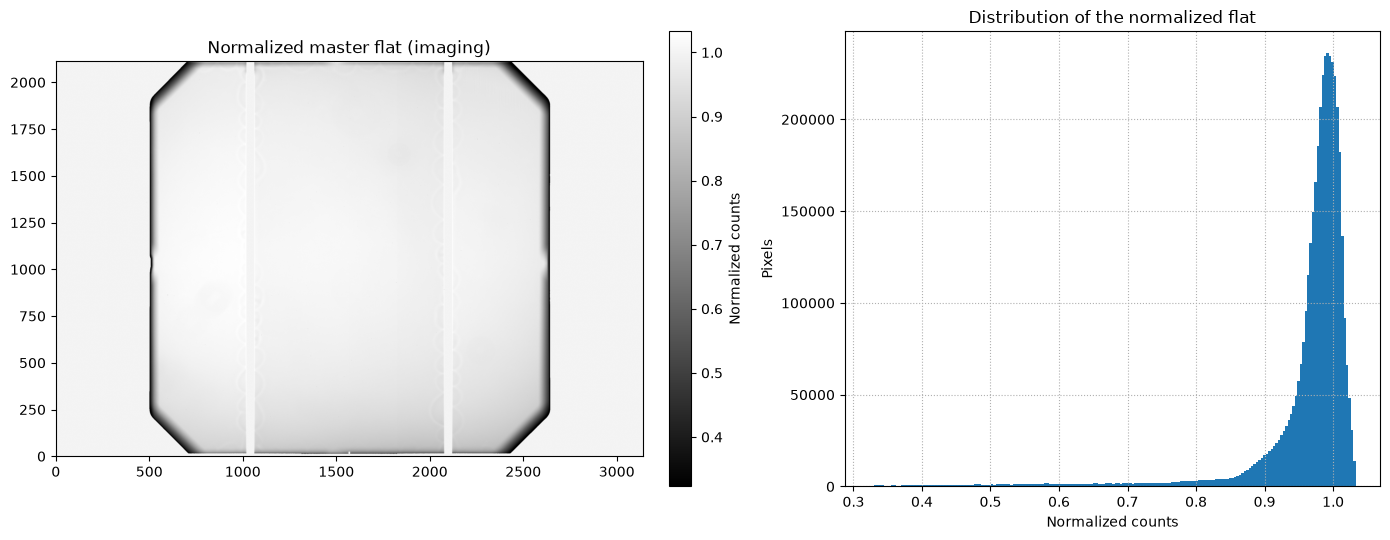

In [9]:
norm_master_flat = cleaning.norm_master_flat(master_flat, method="imaging", illumination_threshold=0.5, low_signal_threshold=0.1,
                                             clip_sigma=3.0, header_hdu_entry=0, plots=True, output_file="norm_master_flat.fits")

In [10]:
flattened_debiased_data = cleaning.flatten(debiased_data=debiased_data, norm_master_flat=norm_master_flat, Type="all")

### Gain, cosmic rays and variance

The converted images are already in electrons (`GAIN = 1` in their headers), so `gain_correct()` only records the gain for the next steps. The cosmic rays are removed with L.A.Cosmic; the saturation level, in electrons, is read from the header of a converted frame.

In [11]:
gain_corrected_data = cleaning.gain_correct(flattened_debiased_data, gain=None, gain_header_entry="GAIN", Type="all", verbose=True)

N20170614S0201.fits: converted from ADU to electrons (gain = 1.0 e-/ADU).
N20170614S0202.fits: converted from ADU to electrons (gain = 1.0 e-/ADU).
N20170614S0203.fits: converted from ADU to electrons (gain = 1.0 e-/ADU).
N20170614S0204.fits: converted from ADU to electrons (gain = 1.0 e-/ADU).
N20170614S0205.fits: converted from ADU to electrons (gain = 1.0 e-/ADU).


In [12]:
first_target_file = sorted((converted_data/"target_starfield").glob("*.fits"))[0]
saturation_level = cleaning.look_in_header(first_target_file, "SATURATE")
print("Saturation level:", saturation_level, "electrons")

CR_corrected_data = cleaning.remove_cosmic_rays(gain_corrected_data, readnoise=None, readnoise_header_entry="RDNOISE", Type="all",
                                                sigclip=5, saturation_level=saturation_level, verbose=True)

Saturation level: 102235.0 electrons
N20170614S0201.fits: 9574 pixels flagged as cosmic rays (0.144% of the image).
N20170614S0202.fits: 9385 pixels flagged as cosmic rays (0.142% of the image).
N20170614S0203.fits: 9561 pixels flagged as cosmic rays (0.144% of the image).
N20170614S0204.fits: 9370 pixels flagged as cosmic rays (0.141% of the image).
N20170614S0205.fits: 9072 pixels flagged as cosmic rays (0.137% of the image).


Let's compare the same image before and after the cosmic-ray removal:

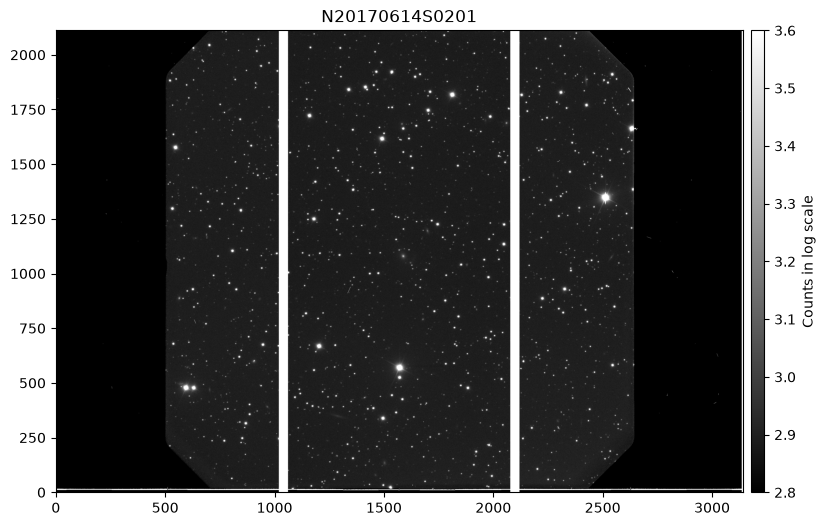

In [13]:
cleaning.plot_images(datacube=flattened_debiased_data, image_type="target", Ncols=1, specific_image=0, vmin=2.8, vmax=3.6,
                     vertical_scale=6)

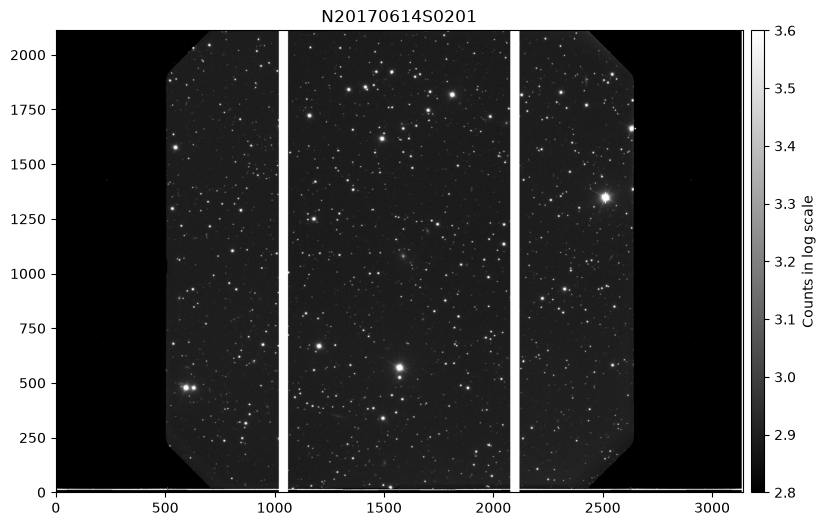

In [14]:
cleaning.plot_images(datacube=CR_corrected_data, image_type="target", Ncols=1, specific_image=0, vmin=2.8, vmax=3.6,
                     vertical_scale=6)

Now we compute the variance (photon noise, read noise, and the noise of the master bias and of the master flat) and the data quality mask of every pixel. The pixels of the CCD gaps and of the bad pixel mask are flagged in the mask (bit 4, non-finite values).

In [15]:
variance, mask = cleaning.compute_variance(CR_corrected_data)

N20170614S0201.fits: gain = 1.0 e-/ADU, read noise = 4.13 e-, dark scale = 0; median S/N per pixel = 27.32; 2413553 flagged pixels.
N20170614S0202.fits: gain = 1.0 e-/ADU, read noise = 4.13 e-, dark scale = 0; median S/N per pixel = 27.00; 2413448 flagged pixels.
N20170614S0203.fits: gain = 1.0 e-/ADU, read noise = 4.13 e-, dark scale = 0; median S/N per pixel = 26.60; 2413458 flagged pixels.
N20170614S0204.fits: gain = 1.0 e-/ADU, read noise = 4.13 e-, dark scale = 0; median S/N per pixel = 26.23; 2413436 flagged pixels.
N20170614S0205.fits: gain = 1.0 e-/ADU, read noise = 4.13 e-, dark scale = 0; median S/N per pixel = 25.91; 2413225 flagged pixels.


## Step 3. Alignment and combination

The 5 exposures are aligned onto the first one: `align()` detects the stars, matches them between the images and finds the shift (and rotation) of each exposure. The variance and the mask follow the images.

With `crop=False`, the full field is kept: where a shifted exposure has no data (outside its field of view, in its CCD gaps or bad pixels), its pixels are NaN. When the exposures are combined with `min_frames=1`, `master()` ignores these pixels and combines the frames that have data, so the gaps of one exposure are filled by the others (by default, `min_frames=None`, a pixel without data in any frame would be NaN in the master).

In [16]:
aligned_data, aligned_variance, aligned_mask = cleaning.align(CR_corrected_data, Type="target", crop=False, fill_value=np.nan,
                                                              variance=variance, mask=mask)

Group 'target_starfield' - reference image: N20170614S0201.fits
  N20170614S0202.fits: method = stars, rotation = +0.000 deg, center shift (dx, dy) = (-6.46, +7.50) px, matched stars = 57, rms = 0.254 px
  N20170614S0203.fits: method = stars, rotation = -0.001 deg, center shift (dx, dy) = (-65.25, +29.26) px, matched stars = 51, rms = 0.297 px
  N20170614S0204.fits: method = stars, rotation = -0.000 deg, center shift (dx, dy) = (-106.47, +152.56) px, matched stars = 48, rms = 0.426 px
  N20170614S0205.fits: method = stars, rotation = -0.002 deg, center shift (dx, dy) = (-57.19, +61.17) px, matched stars = 51, rms = 0.289 px


Finally, the aligned exposures are combined with a median, which also removes the residual cosmic rays and hot pixels. The exposure time and airmass of the master are the averages of the frames. The master image is saved as *master_target_target_starfield.fits*, with its variance ("VAR") and data quality mask ("MASK") extensions:

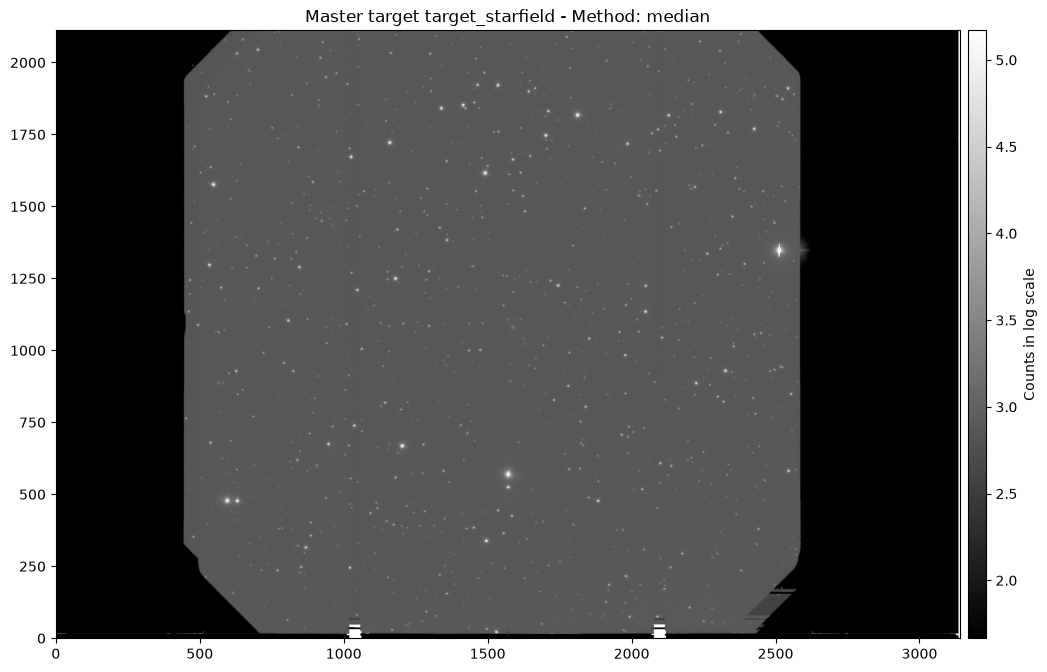

In [17]:
master_target = cleaning.master("target", aligned_data, method="median", header_hdu_entry=0, exposure_header_entry="EXPTIME",
                                airmass_header_entry="AIRMASS", plot=True, variance=aligned_variance, mask=aligned_mask,
                                min_frames=1)

That's it: the image cleaning is done! The CCD gaps are filled, except in a few pixels at the corners of the gaps not covered by any exposure (NaN in the master, flagged with bit 4 in its mask). Faint vertical stripes may still be visible at the positions of the gaps: there, fewer exposures contribute to the median, and the sky level was not the same in all exposures.

The master image can now be analysed with the `photometry()` class of easyspec (source detection, aperture photometry and calibration), as in the photometry tutorials.